# **E G P A**
## **Estimation of Gaussian Process Algorithm**

EGPA is specially suited to solve optimization
problems where decision variables represent a vector
of amplitudes of a discretized function $Z =
f(X) = (f(x_1), f(x_2), ..., f(x_N))$ defined over grid
$X = [x_1, x_2, ..., x_N]$. This function could be
the solution to a given equation or differential equation,
subject, for instance, to constraints imposed
at particular grid points, such as $x_A$ or $x_B$, of
the form $f(x_A) = A$, or constraints on its derivatives,
e.g., $f'(x_B) = B$.

The algorithm follows the scheme of an EDA, but the probabilistic model updated at every iteration is a Gaussian Process. The population at
each generation is composed of many candidate solutions
like f(X) which are sampled from a GP. The best solutions, according to the cost function to be optimized, are used to update the kernel hyperparameters (lenght scale, vertical scale). The new candidate solutions are sampled from the updated GP. This steps are repeated until a convergence criterion is reached.

To test the algorithm we will solve some instances of the Schrödinger equation. The problems below and specially the plots give a lot of insights about the algorithm behaviour!!


### **Solving the Schrödinger Equation with optimization algorithms**

The problem is converted into an optimization problem by discretizing the wavefunction $\Psi(x)$. Each candidate solution is represented by a vector with $n$ elements to be chosen (the discretization); each element represents the amplitude of the wavefunction at a given point:
$$
\Psi(x)\longrightarrow (\Psi(x_1), \Psi(x_2), \ldots, \Psi(x_n)),
$$
bearing in mind that the wavefunction must be normalized:
$$
\int |\Psi(x)|^2\,dx = 1.
$$

The Schrödinger equation is
$$
\hat{H}\lvert\Psi\rangle = E\lvert\Psi\rangle
\quad\longrightarrow\quad
\left(-\frac{\hbar^2}{2m}\frac{d^2}{dx^2}+V(x)\right)\Psi(x)=E\Psi(x).
$$

Once the wavefunction is discretized, the second derivative can be approximated by
$$
\frac{d^2}{dx^2}\Psi(x_n)=
\frac{\Psi(x_{n-1})+\Psi(x_{n+1})-2\Psi(x_n)}{\Delta x^2},
$$
where $\Delta x=x_i-x_{i-1}$ is the spacing of the $x$-coordinate, which will be taken to be constant.


#### **Optimization function based on the expected value of $E$**

Several objective functions are proposed, following different papers. In all of them, an initial guess for the energy $E$ is required. It can be set to zero because the ground-state energy level will be obtained first.
Following *Direct solution of Schrödinger equation by genetic algorithm: test cases* by Saha et al., one possible choice for the optimization function is
$$
Z=\left[\frac{\langle\Psi|\hat{H}|\Psi\rangle}
{\langle\Psi|\Psi\rangle}-E_l\right]^2,
$$
where $E_l$ is a lower bound on the energy. The integrals in the numerator (the expected value of the energy) and denominator are replaced by quadrature sums to integrate the function numerically. The wavefunction is partitioned into $n_{\max}$ pieces. The integration element is $L/n_{\max}$. Thus,
$$
\langle\Psi|\hat{H}|\Psi\rangle =
-\frac{\hbar^2}{2m}\frac{n_{\max}}{L}
\sum_n \Psi(x_n)
\left[\Psi(x_{n-1})+\Psi(x_{n+1})-2\Psi(x_n)\right] + \frac{L}{n_{\max}}\sum_n\Psi(x_n)V(x_n)\Psi(x_n) ,
$$
and
$$
\langle\Psi|\Psi\rangle
=\int\Psi(x)\Psi^*(x)\,dx
=\Delta x\sum_n\Psi(x_n)^2
=\frac{L}{n_{\max}}\sum_n\Psi(x_n)^2.
$$

The optimization function Z can be exponentiated to $F=e^{-Z}$.

**Excited states**

To obtain the following energy levels, it is sufficient to modify the optimization functions by adding a term that sequentially enforces orthogonality between states, $\langle\Psi|\Phi\rangle = 0$. We have already obtained the *ground state* $|\Psi\rangle$ and its energy.

We add a term to the optimization function:

$$
\beta |\langle\Psi|\Phi\rangle|^2
$$

For a function based on the expected energy, this would become:

$$
Z = \left[\frac{\langle\Phi|\hat{H}|\Phi\rangle}{\langle\Phi|\Phi\rangle} - E_l\right]^2 + \beta |\langle\Psi|\Phi\rangle|^2
$$

Where $|\Psi\rangle$ is the previously calculated ground state, $\beta$ is a penalty factor with appropriate dimensions, and we leave the target energy at its previous value.

### **One-dimensional infinite well**

We will solve the one-dimensional problem of a particle of mass $m$ confined to a box of length $L$. The potential is defined as
$$
V(x)=
\begin{cases}
0, & 0<x<L,\\
\infty, & \text{elsewhere}.
\end{cases}
$$

This problem has the analytical solutions
$$
\Psi_n(x)=\sqrt{\frac{2}{L}}\sin\left(\frac{n\pi x}{L}\right),
\qquad
E_n=n^2\frac{h^2}{8L^2m},
\qquad n=1,2,3,\ldots
$$


In [1]:
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add the main directory to sys.path
sys.path.append(main_dir)
from OptFunctions.oneDwellfunctions import *
from EDAspy.optimization import UMDAc
from EGPA import *
from utils import _parallel_apply_along_axis
import warnings
warnings.filterwarnings("ignore")

In [2]:
L=5
n_variables = 51
X_grid = np.linspace(start=0, stop=L, num=n_variables).reshape(-1,1) #para que sean n_variables filas y 1 columna
#Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
#Los datos que conocemos son las amplitudes en x=0 x=5 que son 0
X_train = X_grid[[0,-1]]
Y_train = np.linspace(start=0, stop=0, num=2).reshape(-1,1) #Para que sea 2D array
params = {'L':L}

In [3]:
def Psi_n(n):
    return((2/L)**0.5*np.sin(n*np.pi*np.linspace(0, L, n_variables)/L))

In [4]:
Gaussian = EGPA(size_gen=500, grid_X=X_grid, max_iter=200, dead_iter=20, alpha=0.1, elite_factor=0.05, init_kernels=5 ,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultground = Gaussian.minimize(oneD_wellExpE, params, exp_from = 2, output_runtime=True)

IT:  0 	Best cost:  0.03969357218549497
IT:  1 	Best cost:  -0.9617719602343123
IT:  2 	Best cost:  -0.9618014338293979
IT:  3 	Best cost:  -0.9618014338293979
IT:  4 	Best cost:  -0.9618014338293979
IT:  5 	Best cost:  -0.961803240192255
IT:  6 	Best cost:  -0.961803240192255
IT:  7 	Best cost:  -0.961803240192255
IT:  8 	Best cost:  -0.961803240192255
IT:  9 	Best cost:  -0.9618032805308058
IT:  10 	Best cost:  -0.961803700241997
IT:  11 	Best cost:  -0.961803700241997
IT:  12 	Best cost:  -0.961803700241997
IT:  13 	Best cost:  -0.961803700241997
IT:  14 	Best cost:  -0.961803700241997
IT:  15 	Best cost:  -0.961803700241997
IT:  16 	Best cost:  -0.961803700241997
IT:  17 	Best cost:  -0.961803700241997
IT:  18 	Best cost:  -0.9618038574375705
IT:  19 	Best cost:  -0.9618038574375705
IT:  20 	Best cost:  -0.9618038574375705
IT:  21 	Best cost:  -0.9618038574375705
IT:  22 	Best cost:  -0.9618038574375705
IT:  23 	Best cost:  -0.9618038574375705
IT:  24 	Best cost:  -0.96180385743757

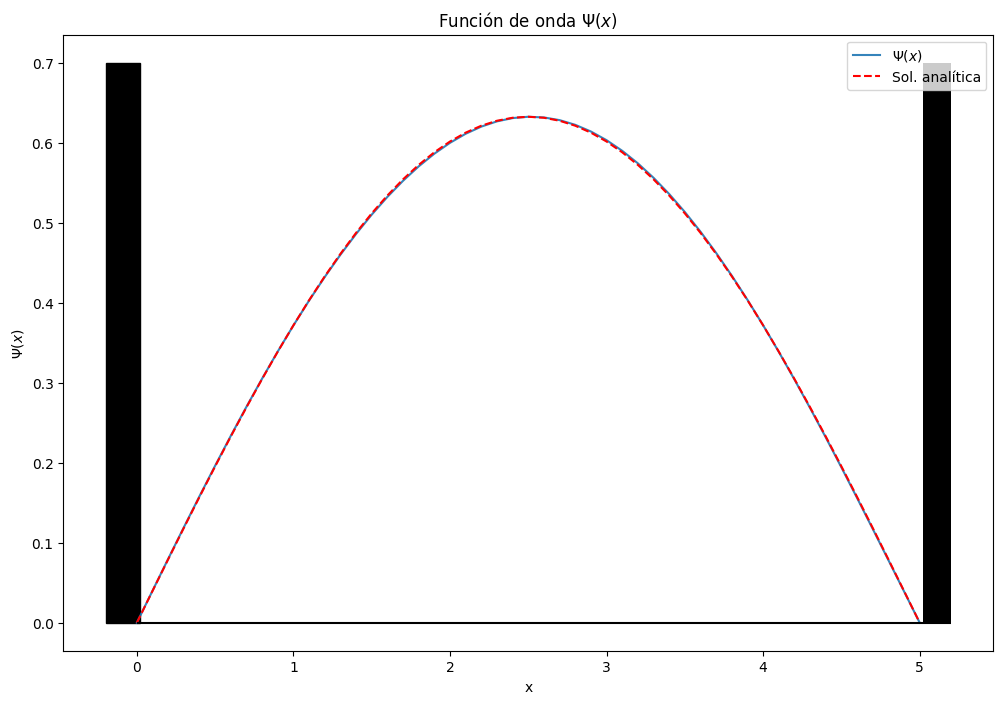

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(0, 5, n_variables),egparesultground.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(0, 5, n_variables), Psi_n(1), 'r--', label='Sol. analítica')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, 0.02, 0.02]
x2 = [5.02, 5.02, 5.2, 5.2]
y = [0, 0.7, 0.7, 0]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

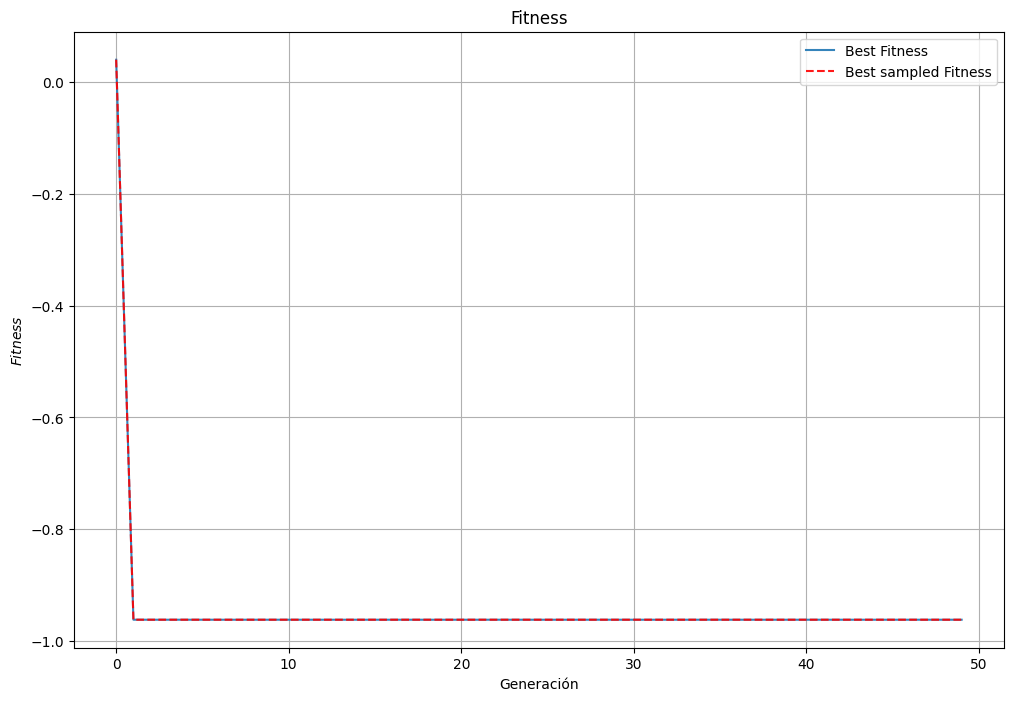

In [6]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.arange(0, len(egparesultground.data), 1),egparesultground.data[:,0,-1], '-', label='Best Fitness', alpha=0.9)
plt.plot(np.arange(0, len(egparesultground.data), 1),egparesultground.best_sampled[:, 0, -1], 'r--', label='Best sampled Fitness', alpha=0.9)
# plt.ylim((-1, 0.2))
# plt.xlim((38, 75))
plt.grid()
plt.gca().set_title(r'Fitness')
plt.xlabel('Generación')
plt.gca().set_ylabel(r'$Fitness$')
plt.legend(loc = 'upper right');

In [7]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_06(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(len(egparesultground.data))):
        plt.plot(np.linspace(0, 5, n_variables), egparesultground.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.plot(np.linspace(0, 5, n_variables), Psi_n(1), 'k-', label='Sol. analítica')
    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    # Define the vertices of the rectangle
    x = [-0.2, -0.2, 0.02, 0.02]
    x2 = [5.02, 5.02, 5.2, 5.2]
    y = [0, 0.7, 0.7, 0]
    # Fill the area defined by the vertices
    plt.fill(x, y, color='black')
    plt.fill(x2, y, 'black')
    plt.hlines(y=0, xmin=0, xmax=5.2, colors='k')
    plt.legend();

#Create a slider widget
generation_slider_cell_06 = widgets.IntSlider(value=0, min=0, max=len(egparesultground.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_06 function
interact(update_plot_cell_06, i=generation_slider_cell_06);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=49), Outpu…

In [8]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

# Interactive posterior mean and 95% confidence interval for eigenstate n=1.
def update_infinite_well_ci_state_1(generation):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 8))
    mean_prediction, std_prediction = egparesultground.GP_hist[generation].predict(X_grid, return_std=True)
    x_values = X_grid.ravel()

    ax.plot(x_values, mean_prediction, label="GP mean prediction")
    ax.fill_between(
        x_values,
        mean_prediction - 1.96 * std_prediction,
        mean_prediction + 1.96 * std_prediction,
        alpha=0.35,
        label="95% confidence interval",
    )
    ax.plot(x_values, Psi_n(1), "r--", label="Analytical solution")
    ax.set_title(f"Infinite well: eigenstate n=1, generation {generation}")
    ax.set_xlabel("x")
    ax.set_ylabel(r"$\Psi(x)$")
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()

infinite_well_generation_slider_1 = widgets.IntSlider(
    value=0,
    min=0,
    max=len(egparesultground.GP_hist) - 1,
    step=1,
    description="Generation",
    layout=widgets.Layout(width="100%"),
)
interact(update_infinite_well_ci_state_1, generation=infinite_well_generation_slider_1);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=48), Outpu…

In [9]:
Psi_fund=egparesultground.data[-1, 0, :-1]
E_fund = np.sqrt(-np.log(-egparesultground.data[-1,0,-1])) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'L':L, 'E': E_fund, 'Psi': Psi_fund}

In [10]:
np.mean(abs(Psi_n(0)-Psi_fund))

np.float64(0.39456796889787266)

In [ ]:
Gaussian = EGPA(size_gen=500, grid_X=X_grid, max_iter=200, dead_iter=50, alpha=0.1, elite_factor=0.05, init_kernels=5,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultexc1 = Gaussian.minimize(oneD_wellExpEexcitated, params, exp_from = 4, output_runtime=True)

IT:  0 	Best cost:  0.36872846491889316
IT:  1 	Best cost:  0.35601926732954275
IT:  2 	Best cost:  0.3527414097156877
IT:  3 	Best cost:  -0.7038863551807526
IT:  4 	Best cost:  -0.7038863551807526
IT:  5 	Best cost:  -0.7038863551807526
IT:  6 	Best cost:  -0.7042909568170681
IT:  7 	Best cost:  -0.7042909568170681
IT:  8 	Best cost:  -0.7042909568170681
IT:  9 	Best cost:  -0.7042909568170681
IT:  10 	Best cost:  -0.7042909568170681
IT:  11 	Best cost:  -0.7042909568170681
IT:  12 	Best cost:  -0.7042909568170681
IT:  13 	Best cost:  -0.7042909568170681
IT:  14 	Best cost:  -0.7042909568170681
IT:  15 	Best cost:  -0.7042909568170681
IT:  16 	Best cost:  -0.7042909568170681
IT:  17 	Best cost:  -0.7043333314260831
IT:  18 	Best cost:  -0.7043333314260831
IT:  19 	Best cost:  -0.7043333314260831
IT:  20 	Best cost:  -0.7043333314260831
IT:  21 	Best cost:  -0.7043333314260831


Exception ignored in: <function _releaseLock at 0x7f40961b3880>
Traceback (most recent call last):
  File "/home/dani/anaconda3/envs/EDAspy/lib/python3.12/logging/__init__.py", line 243, in _releaseLock
    def _releaseLock():
    
KeyboardInterrupt: 


IT:  22 	Best cost:  -0.7043333314260831
IT:  23 	Best cost:  -0.7043333314260831
IT:  24 	Best cost:  -0.7043333314260831
IT:  25 	Best cost:  -0.7043333314260831
IT:  26 	Best cost:  -0.7043333314260831
IT:  27 	Best cost:  -0.7043333314260831
IT:  28 	Best cost:  -0.7043333314260831
IT:  29 	Best cost:  -0.7043333314260831
IT:  30 	Best cost:  -0.7043333314260831
IT:  31 	Best cost:  -0.7043333314260831
IT:  32 	Best cost:  -0.7043333314260831
IT:  33 	Best cost:  -0.7043333314260831
IT:  34 	Best cost:  -0.7043333314260831
IT:  35 	Best cost:  -0.7043333314260831
IT:  36 	Best cost:  -0.7043333314260831
IT:  37 	Best cost:  -0.7043333314260831
IT:  38 	Best cost:  -0.7043333314260831
IT:  39 	Best cost:  -0.7043333314260831
IT:  40 	Best cost:  -0.7043333314260831
IT:  41 	Best cost:  -0.7043333314260831
IT:  42 	Best cost:  -0.7043333314260831
IT:  43 	Best cost:  -0.7043333314260831
IT:  44 	Best cost:  -0.7043333314260831
IT:  45 	Best cost:  -0.7043333314260831
IT:  46 	Best co

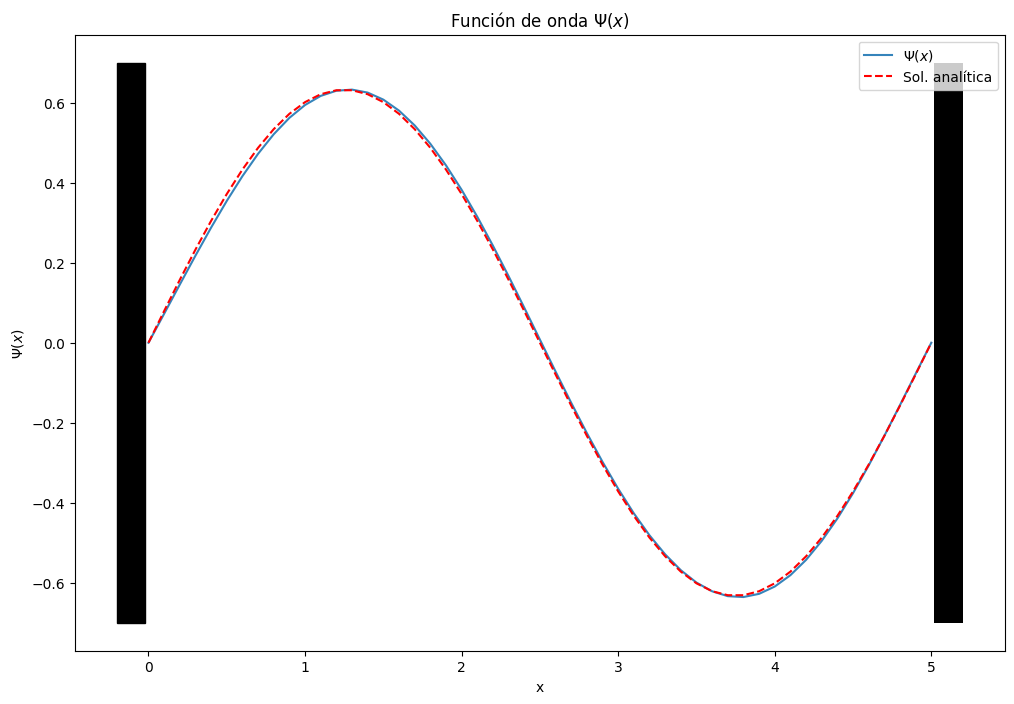

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(0, 5, n_variables),egparesultexc1.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(0, 5, n_variables), Psi_n(2), 'r--', label='Sol. analítica')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, -0.02, -0.02]
x2 = [5.02, 5.02, 5.2, 5.2]
y = [-0.70, 0.7, 0.7, -0.7]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
#plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

In [ ]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_12(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(len(egparesultexc1.data)):
        plt.plot(np.linspace(0, 5, n_variables), egparesultexc1.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.plot(np.linspace(0, 5, n_variables), Psi_n(2), 'k-', label='Sol. analítica')
    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    # Define the vertices of the rectangle
    x = [-0.2, -0.2, -0.02, -0.02]
    x2 = [5.02, 5.02, 5.2, 5.2]
    y = [-0.70, 0.7, 0.7, -0.7]
    # Fill the area defined by the vertices
    plt.fill(x, y, color='black')
    plt.fill(x2, y, 'black')
    plt.hlines(y=0, xmin=0, xmax=5.2, colors='k')
    plt.legend();

#Create a slider widget
generation_slider_cell_12 = widgets.IntSlider(value=0, min=0, max=len(egparesultexc1.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_12 function
interact(update_plot_cell_12, i=generation_slider_cell_12);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=123), Outp…

In [ ]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

# Interactive posterior mean and 95% confidence interval for eigenstate n=2.
def update_infinite_well_ci_state_2(generation):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 8))
    mean_prediction, std_prediction = egparesultexc1.GP_hist[generation].predict(X_grid, return_std=True)
    x_values = X_grid.ravel()

    ax.plot(x_values, mean_prediction, label="GP mean prediction")
    ax.fill_between(
        x_values,
        mean_prediction - 1.96 * std_prediction,
        mean_prediction + 1.96 * std_prediction,
        alpha=0.35,
        label="95% confidence interval",
    )
    ax.plot(x_values, Psi_n(2), "r--", label="Analytical solution")
    ax.set_title(f"Infinite well: eigenstate n=2, generation {generation}")
    ax.set_xlabel("x")
    ax.set_ylabel(r"$\Psi(x)$")
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()

infinite_well_generation_slider_2 = widgets.IntSlider(
    value=0,
    min=0,
    max=len(egparesultexc1.GP_hist) - 1,
    step=1,
    description="Generation",
    layout=widgets.Layout(width="100%"),
)
interact(update_infinite_well_ci_state_2, generation=infinite_well_generation_slider_2);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=122), Outp…

In [ ]:
Psi_1=egparesultexc1.data[-1, 0, :-1]
E1 = np.sqrt(-np.log(-egparesultexc1.data[-1,0,-1])) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1}

In [ ]:
Gaussian = EGPA(size_gen=600, grid_X=X_grid, max_iter=600, dead_iter=60, alpha=0.1, elite_factor=0.05, init_kernels=6,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultexc2 = Gaussian.minimize(oneD_wellExpEexcitated3, params, exp_from = 5, output_runtime=True)

IT:  0 	Best cost:  1.401051767744728
IT:  1 	Best cost:  1.129583849966904
IT:  2 	Best cost:  0.9878856096562469
IT:  3 	Best cost:  0.9798443054863677
IT:  4 	Best cost:  -0.37587351317188256
IT:  5 	Best cost:  -0.3786466208171364
IT:  6 	Best cost:  -0.3786466208171364
IT:  7 	Best cost:  -0.3786466208171364
IT:  8 	Best cost:  -0.3786466208171364
IT:  9 	Best cost:  -0.3786466208171364
IT:  10 	Best cost:  -0.3786466208171364
IT:  11 	Best cost:  -0.3786466208171364
IT:  12 	Best cost:  -0.3786466208171364
IT:  13 	Best cost:  -0.3786466208171364
IT:  14 	Best cost:  -0.37879452936867103
IT:  15 	Best cost:  -0.37879452936867103
IT:  16 	Best cost:  -0.37879452936867103
IT:  17 	Best cost:  -0.37879452936867103
IT:  18 	Best cost:  -0.37879452936867103
IT:  19 	Best cost:  -0.37879452936867103
IT:  20 	Best cost:  -0.37879452936867103
IT:  21 	Best cost:  -0.37879452936867103
IT:  22 	Best cost:  -0.37879452936867103
IT:  23 	Best cost:  -0.37879452936867103
IT:  24 	Best cost:  

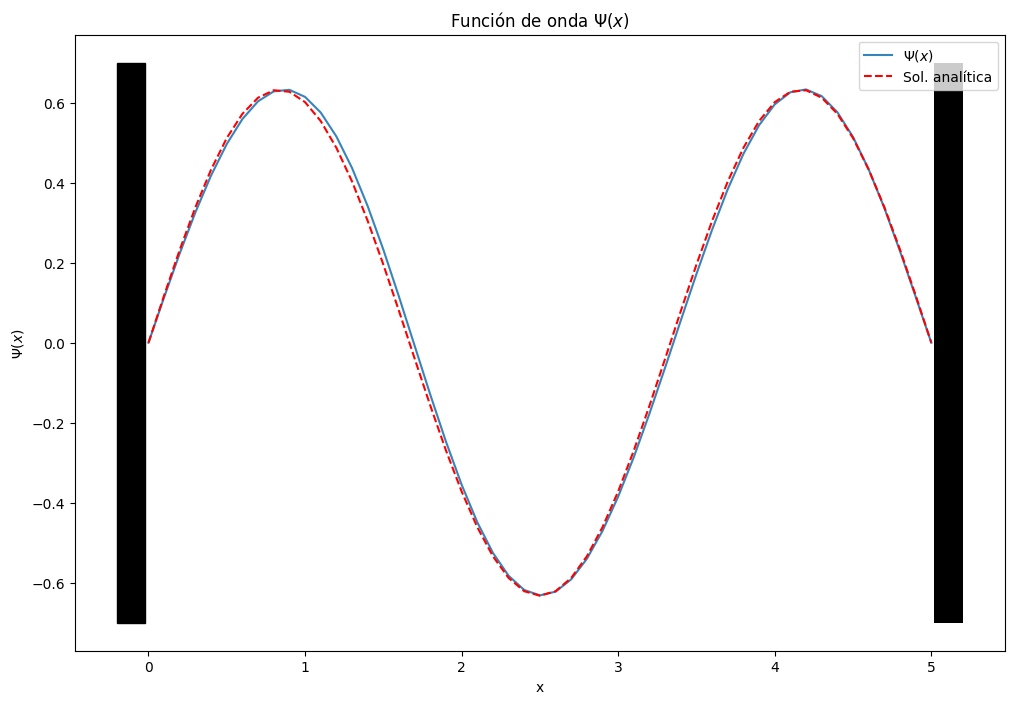

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(0, 5, n_variables),egparesultexc2.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(0, 5, n_variables), Psi_n(3), 'r--', label='Sol. analítica')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, -0.02, -0.02]
x2 = [5.02, 5.02, 5.2, 5.2]
y = [-0.70, 0.7, 0.7, -0.7]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
#plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

In [ ]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_17(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(len(egparesultexc2.data))):
        plt.plot(np.linspace(0, 5, n_variables), egparesultexc2.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.plot(np.linspace(0, 5, n_variables), Psi_n(3), 'k-', label='Sol. analítica')
    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    # Define the vertices of the rectangle
    x = [-0.2, -0.2, -0.02, -0.02]
    x2 = [5.02, 5.02, 5.2, 5.2]
    y = [-0.70, 0.7, 0.7, -0.7]
    # Fill the area defined by the vertices
    plt.fill(x, y, color='black')
    plt.fill(x2, y, 'black')
    plt.hlines(y=0, xmin=0, xmax=5.2, colors='k')
    plt.legend();

#Create a slider widget
generation_slider_cell_17 = widgets.IntSlider(value=0, min=0, max=len(egparesultexc2.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_17 function
interact(update_plot_cell_17, i=generation_slider_cell_17);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=180), Outp…

In [ ]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

# Interactive posterior mean and 95% confidence interval for eigenstate n=3.
def update_infinite_well_ci_state_3(generation):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 8))
    mean_prediction, std_prediction = egparesultexc2.GP_hist[generation].predict(X_grid, return_std=True)
    x_values = X_grid.ravel()

    ax.plot(x_values, mean_prediction, label="GP mean prediction")
    ax.fill_between(
        x_values,
        mean_prediction - 1.96 * std_prediction,
        mean_prediction + 1.96 * std_prediction,
        alpha=0.35,
        label="95% confidence interval",
    )
    ax.plot(x_values, Psi_n(3), "r--", label="Analytical solution")
    ax.set_title(f"Infinite well: eigenstate n=3, generation {generation}")
    ax.set_xlabel("x")
    ax.set_ylabel(r"$\Psi(x)$")
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()

infinite_well_generation_slider_3 = widgets.IntSlider(
    value=0,
    min=0,
    max=len(egparesultexc2.GP_hist) - 1,
    step=1,
    description="Generation",
    layout=widgets.Layout(width="100%"),
)
interact(update_infinite_well_ci_state_3, generation=infinite_well_generation_slider_3);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=179), Outp…

In [ ]:
Psi_2=egparesultexc2.data[-1, 0, :-1]
E2 = np.sqrt(-np.log(-egparesultexc2.data[-1,0,-1])) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'L':L, 'E0': E_fund, 'Psi0': Psi_fund, 'E1':E1, 'Psi1': Psi_1, 'E2': E2, 'Psi2': Psi_2}

In [ ]:
Gaussian = EGPA(size_gen=600, grid_X=X_grid, max_iter=600, dead_iter=60, alpha=0.1, elite_factor=0.05, init_kernels=6,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultexc3 = Gaussian.minimize(oneD_wellExpEexcitated4, params, exp_from = 10, output_runtime=True)

IT:  0 	Best cost:  4.248340726852669
IT:  1 	Best cost:  4.248340726852669
IT:  2 	Best cost:  3.0716140479431226
IT:  3 	Best cost:  3.0716140479431226
IT:  4 	Best cost:  3.0716140479431226
IT:  5 	Best cost:  3.0716140479431226
IT:  6 	Best cost:  3.0716140479431226
IT:  7 	Best cost:  2.595995984330301
IT:  8 	Best cost:  2.0982830783860713
IT:  9 	Best cost:  -0.1336481392961039
IT:  10 	Best cost:  -0.14609402255807621
IT:  11 	Best cost:  -0.14609402255807621
IT:  12 	Best cost:  -0.1472405795890044
IT:  13 	Best cost:  -0.150824409102678
IT:  14 	Best cost:  -0.150824409102678
IT:  15 	Best cost:  -0.150824409102678
IT:  16 	Best cost:  -0.1524924763281954
IT:  17 	Best cost:  -0.15271215429009014
IT:  18 	Best cost:  -0.15271215429009014
IT:  19 	Best cost:  -0.15271215429009014
IT:  20 	Best cost:  -0.15271215429009014
IT:  21 	Best cost:  -0.15271215429009014
IT:  22 	Best cost:  -0.15271215429009014
IT:  23 	Best cost:  -0.15271215429009014
IT:  24 	Best cost:  -0.15271215

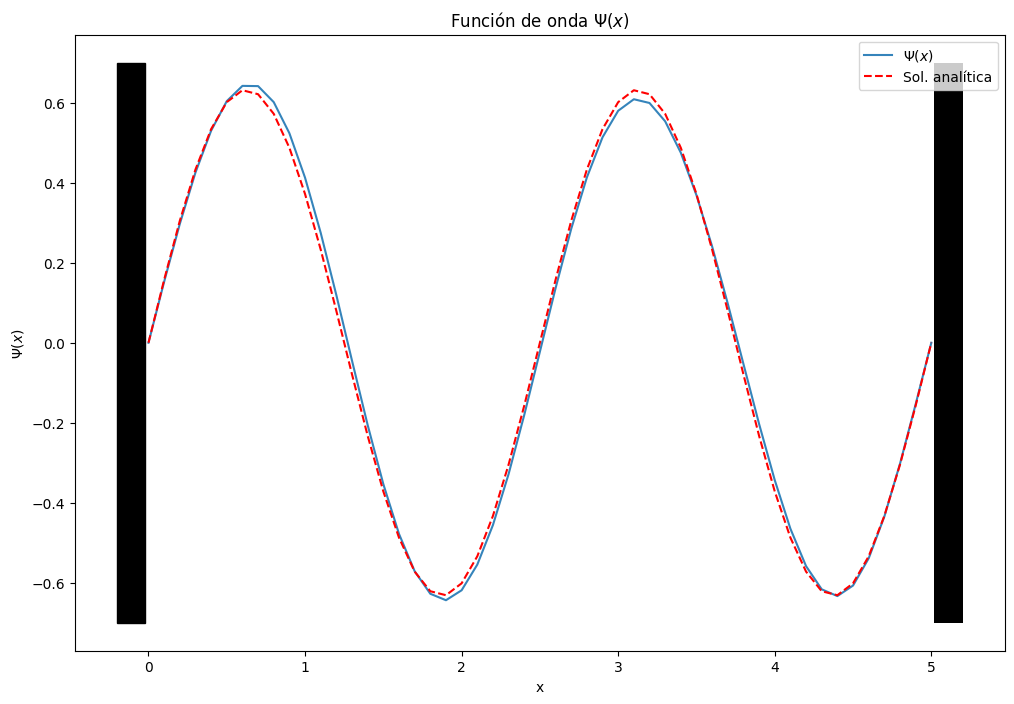

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(0, 5, n_variables),egparesultexc3.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(0, 5, n_variables), Psi_n(4), 'r--', label='Sol. analítica')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right')
# Define the vertices of the rectangle
x = [-0.2, -0.2, -0.02, -0.02]
x2 = [5.02, 5.02, 5.2, 5.2]
y = [-0.70, 0.7, 0.7, -0.7]
# Fill the area defined by the vertices
plt.fill(x, y, color='black')
plt.fill(x2, y, 'black')
#plt.hlines(y=0, xmin=0, xmax=5.2, colors='k');

In [ ]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_22(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(len(egparesultexc3.data))):
        plt.plot(np.linspace(0, 5, n_variables), egparesultexc3.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.plot(np.linspace(0, 5, n_variables), Psi_n(4), 'k-', label='Sol. analítica')
    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    # Define the vertices of the rectangle
    x = [-0.2, -0.2, -0.02, -0.02]
    x2 = [5.02, 5.02, 5.2, 5.2]
    y = [-0.70, 0.7, 0.7, -0.7]
    # Fill the area defined by the vertices
    plt.fill(x, y, color='black')
    plt.fill(x2, y, 'black')
    plt.hlines(y=0, xmin=0, xmax=5.2, colors='k')
    plt.legend();

#Create a slider widget
generation_slider_cell_22 = widgets.IntSlider(value=0, min=0, max=len(egparesultexc3.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_22 function
interact(update_plot_cell_22, i=generation_slider_cell_22);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=77), Outpu…

In [ ]:
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

# Interactive posterior mean and 95% confidence interval for eigenstate n=4.
def update_infinite_well_ci_state_4(generation):
    plt.clf()
    fig, ax = plt.subplots(figsize=(12, 8))
    mean_prediction, std_prediction = egparesultexc3.GP_hist[generation].predict(X_grid, return_std=True)
    x_values = X_grid.ravel()

    ax.plot(x_values, mean_prediction, label="GP mean prediction")
    ax.fill_between(
        x_values,
        mean_prediction - 1.96 * std_prediction,
        mean_prediction + 1.96 * std_prediction,
        alpha=0.35,
        label="95% confidence interval",
    )
    ax.plot(x_values, Psi_n(4), "r--", label="Analytical solution")
    ax.set_title(f"Infinite well: eigenstate n=4, generation {generation}")
    ax.set_xlabel("x")
    ax.set_ylabel(r"$\Psi(x)$")
    ax.grid(True, alpha=0.25)
    ax.legend()
    fig.tight_layout()

infinite_well_generation_slider_4 = widgets.IntSlider(
    value=0,
    min=0,
    max=len(egparesultexc3.GP_hist) - 1,
    step=1,
    description="Generation",
    layout=widgets.Layout(width="100%"),
)
interact(update_infinite_well_ci_state_4, generation=infinite_well_generation_slider_4);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=76), Outpu…

# **Quantum harmonic oscillator**

Another typical problem is the harmonic oscillator (classically arising from a force of the form $F = -kx$). In this case, the potential is $V(x) = \frac{1}{2}m\omega^2 x^2$, where $x$ is the displacement from the equilibrium position (the potential well), so the Hamiltonian is written as:

$$\hat{H} | \Psi\rangle = E | \Psi\rangle \quad \longrightarrow \quad
\left(-\frac{\hbar^2}{2m}\frac{d^2}{dx^2} + V(x)\right)\Psi(x) \longrightarrow \quad \left(-\frac{\hbar^2}{2m}\frac{d^2}{dx^2} + \frac{1}{2}m\omega^2 x^2 \right)\Psi(x)= E \Psi(x)$$

The analytical solutions depend on Hermite polynomials, with their corresponding energies:

$$ \Psi_n = N_n e^{-\beta^2 x^2 / 2} H_n (\beta x ) \quad ; \quad E_n = (n + \frac{1}{2}) \hbar \omega \quad \text{with} \,\,\, n = 0, 1, 2, ...$$

where $N_n$ is the normalization constant for each solution, $\beta = \sqrt{m \omega / \hbar}$, and $H_n(y)$ is the Hermite polynomial of degree $n$, which has the following forms:

$$H_0(y) = 1 \quad H_1(y) = 2y \quad H_2(y) = 4y^2 - 2 \quad H_3(y) = 8y^3 - 12y$$

We will use the following optimization function:

$$ Z = \left[\frac{\langle\Psi|\hat{H}|\Psi\rangle}{\langle\Psi|\Psi\rangle} - E_l\right]^2 $$

In [ ]:
from EGPA import *
from OptFunctions.oneDQHarmOscillatorfunctions import *
from utils import _parallel_apply_along_axis
import warnings
warnings.filterwarnings("ignore")

In [ ]:
n_variables = 51
X_grid = np.linspace(start=-4, stop=4, num=n_variables).reshape(-1,1) #para que sean n_variables filas y 1 columna
#Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
#Los datos que conocemos son las amplitudes en x=-4 (-inf) x=4 (inf) que son 0
X_train = X_grid[[0,-1]]
Y_train = np.linspace(start=0, stop=0, num=2).reshape(-1,1) #Para que sea 2D array
params = {'x':X_grid}

In [ ]:
#Analytical solutions definitions

#Ground state
APsi0 = np.exp(-X_grid**2/2)
integral =0
for i in range(len(APsi0)):
    integral = integral + (APsi0[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi0)-1))

B = (1/integral)**0.5
APsi0 = B * APsi0

#1st excitated state
APsi1 = np.exp(-X_grid**2/2)*2*X_grid
integral =0
for i in range(len(APsi1)):
    integral = integral + (APsi1[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi1)-1))

B = (1/integral)**0.5
APsi1 = B * APsi1

#if results_dict['eda_resultExpE1'].sel_inds_hist[-1, 0, :-1][10]>0:
   # APsi1 = -APsi1


#2nd excitated state
APsi2 = np.exp(-X_grid**2/2)*(4*X_grid**2-2)
integral =0
for i in range(len(APsi2)):
    integral = integral + (APsi2[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi2)-1))

B = (1/integral)**0.5
APsi2 = B * APsi2

#if results_dict['eda_resultExpE2'].sel_inds_hist[-1, 0, :-1][3]<0:
   # APsi2=-APsi2

#3rd excitated state
APsi3 = np.exp(-X_grid**2/2)*(8*X_grid**3-12*X_grid)
integral =0
for i in range(len(APsi3)):
    integral = integral + (APsi3[i]**2)*((X_grid[-1]-X_grid[0])/(len(APsi3)-1))

B = (1/integral)**0.5
APsi3 = B * APsi3

#if results_dict['eda_resultExpE3'].sel_inds_hist[-1,0,:-1][10]>0:
   # APsi3 = -APsi3 

In [ ]:
Gaussian = EGPA(size_gen=400, grid_X=X_grid, max_iter=300, dead_iter=30, alpha=0.1, elite_factor=0.05, init_kernels=4,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultQHOground = Gaussian.minimize(oneDHOExpE, params, exp_from = 3, output_runtime=True)

IT:  0 	Best cost:  [0.28874864]
IT:  1 	Best cost:  [0.28874864]
IT:  2 	Best cost:  [-0.0464648]
IT:  3 	Best cost:  [-0.05845707]
IT:  4 	Best cost:  [-0.06249623]
IT:  5 	Best cost:  [-0.06644714]
IT:  6 	Best cost:  [-0.06827578]
IT:  7 	Best cost:  [-0.06900549]
IT:  8 	Best cost:  [-0.06919036]
IT:  9 	Best cost:  [-0.06919036]
IT:  10 	Best cost:  [-0.07485024]
IT:  11 	Best cost:  [-0.07485024]
IT:  12 	Best cost:  [-0.07485024]
IT:  13 	Best cost:  [-0.07485024]
IT:  14 	Best cost:  [-0.07661663]
IT:  15 	Best cost:  [-0.07661663]
IT:  16 	Best cost:  [-0.07661663]
IT:  17 	Best cost:  [-0.07661663]
IT:  18 	Best cost:  [-0.07661663]
IT:  19 	Best cost:  [-0.07661663]
IT:  20 	Best cost:  [-0.07661663]
IT:  21 	Best cost:  [-0.07661663]
IT:  22 	Best cost:  [-0.07661663]
IT:  23 	Best cost:  [-0.07661663]
IT:  24 	Best cost:  [-0.07661663]
IT:  25 	Best cost:  [-0.07661663]
IT:  26 	Best cost:  [-0.07661663]
IT:  27 	Best cost:  [-0.07661663]
IT:  28 	Best cost:  [-0.07661663

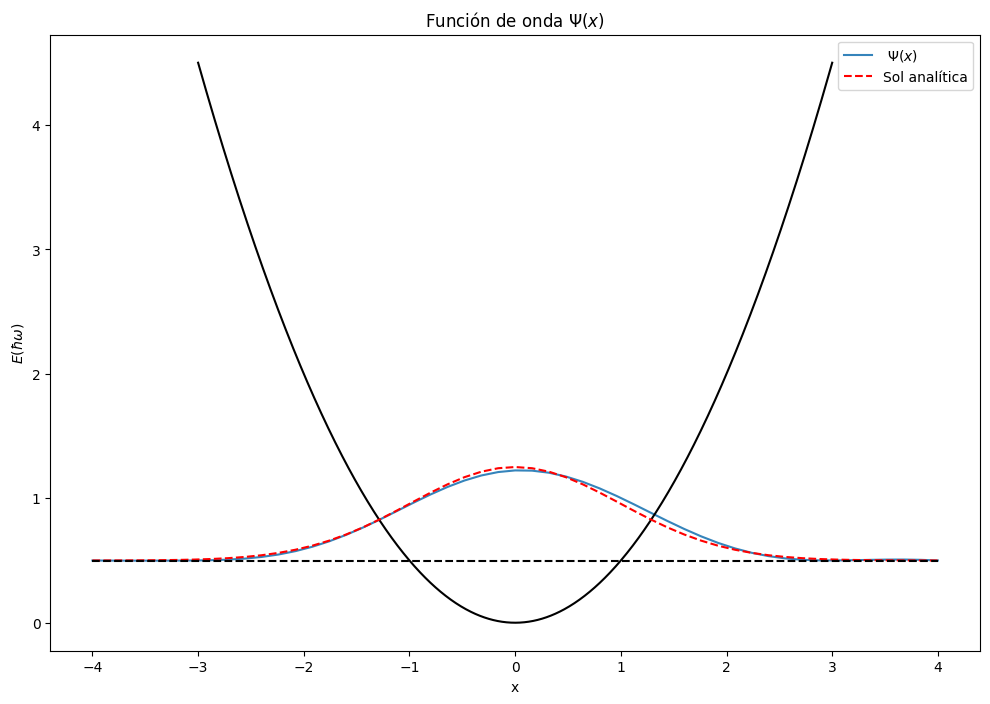

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
plt.plot(X_grid, 0.5+egparesultQHOground.data[-1, 0, :-1], '-', label=f' $\Psi(x)$', alpha=0.9)

plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
plt.plot(np.linspace(-4,4,n_variables), 0.5+APsi0, 'r--', label='Sol analítica')
plt.plot(np.linspace(-4,4,2), np.linspace(0.5,0.5,2), 'k--')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E (\hbar \omega)$')
plt.legend();

In [ ]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_30(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 10))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(egparesultQHOground.data.shape[1]*0.1)):
        plt.plot(X_grid, 0.5+egparesultQHOground.data[i,inds,:-1])#, label='Mejores soluciones')

    #plt.plot(X_grid, APsi0, 'k-', label='Sol. analítica')
    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(X_grid, 0.5+APsi0, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(0.5,0.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_30 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHOground.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_30 function
interact(update_plot_cell_30, i=generation_slider_cell_30);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=44), Outpu…

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_31(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultQHOground.GP_hist[i].predict(X_grid, return_std=True)
    plt.plot(X_grid, 0.5+mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid.ravel(),
        0.5+ mean_prediction - 1.96 * std_prediction,
        0.5+mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 0.5+1*APsi0, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(0.5,0.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_31 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHOground.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_31 function
interact(update_plot_cell_31, i=generation_slider_cell_31);

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=44), Outpu…

In [ ]:
Psi_ground=egparesultQHOground.data[-1, 0, :-1]
cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
E0 = np.sqrt(-np.log(-egparesultQHOground.data[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así 
params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground}

In [ ]:
Gaussian = EGPA(size_gen=400, grid_X=X_grid, max_iter=300, dead_iter=30, alpha=0.05, elite_factor=0.025, init_kernels=4,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultQHO1 = Gaussian.minimize(oneDHOExpE1, params, exp_from = 5, output_runtime=True)

IT:  0 	Best cost:  [1.37041104]
IT:  1 	Best cost:  [1.37041104]
IT:  2 	Best cost:  [1.31431604]
IT:  3 	Best cost:  [1.12392905]
IT:  4 	Best cost:  [-2.69421847e-05]
IT:  5 	Best cost:  [-4.31830761e-05]
IT:  6 	Best cost:  [-4.31830761e-05]
IT:  7 	Best cost:  [-4.31830761e-05]
IT:  8 	Best cost:  [-4.31830761e-05]
IT:  9 	Best cost:  [-4.71443641e-05]
IT:  10 	Best cost:  [-4.71443641e-05]
IT:  11 	Best cost:  [-4.71443641e-05]
IT:  12 	Best cost:  [-4.71443641e-05]
IT:  13 	Best cost:  [-4.71443641e-05]
IT:  14 	Best cost:  [-4.71443641e-05]
IT:  15 	Best cost:  [-5.09561935e-05]
IT:  16 	Best cost:  [-5.09561935e-05]
IT:  17 	Best cost:  [-5.09561935e-05]
IT:  18 	Best cost:  [-5.09561935e-05]
IT:  19 	Best cost:  [-5.09561935e-05]
IT:  20 	Best cost:  [-5.09561935e-05]
IT:  21 	Best cost:  [-5.09561935e-05]
IT:  22 	Best cost:  [-5.09561935e-05]
IT:  23 	Best cost:  [-5.09561935e-05]
IT:  24 	Best cost:  [-5.36088175e-05]
IT:  25 	Best cost:  [-5.36088175e-05]
IT:  26 	Best co

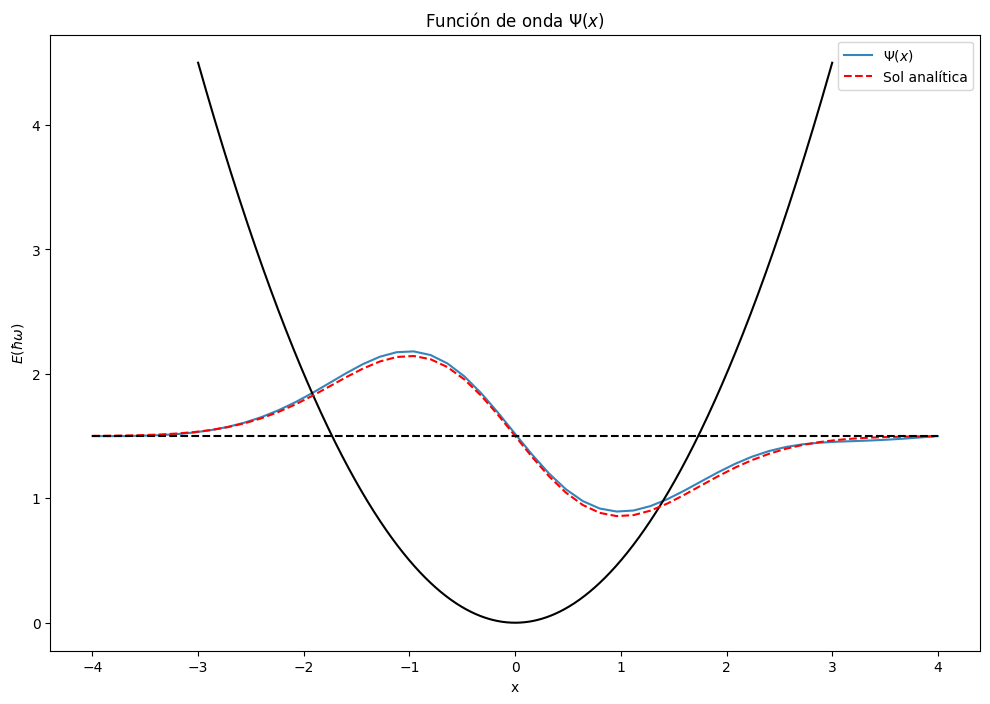

In [ ]:
plt.figure(figsize=(12, 8))
plt.plot(X_grid, 1.5+egparesultQHO1.data[-1,0,:-1], '-', label=f'$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
plt.plot(X_grid, 1.5+-1*APsi1, 'r--', label='Sol analítica')
plt.plot(np.linspace(-4,4,2), np.linspace(1.5,1.5,2), 'k--')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E(\hbar \omega)$')
plt.legend();

In [ ]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_35(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(egparesultQHO1.data.shape[1])):
        plt.plot(X_grid, 1.5+egparesultQHO1.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 1.5+-1*APsi1, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(1.5,1.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_35 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO1.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_35 function
interact(update_plot_cell_35, i=generation_slider_cell_35);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=54), Outpu…

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_36(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultQHO1.GP_hist[i].predict(X_grid, return_std=True)
    plt.plot(X_grid, 1.5+mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid.ravel(),
        1.5+ mean_prediction - 1.96 * std_prediction,
        1.5+mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 1.5+-1*APsi1, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(1.5,1.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_36 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO1.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_36 function
interact(update_plot_cell_36, i=generation_slider_cell_36);

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=54), Outpu…

In [ ]:
Psi1=egparesultQHO1.data[-1, 0, :-1]
cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
E1 = np.sqrt(-np.log(-egparesultQHO1.data[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground, 'E1':E1, 'Psi1': Psi1}

In [ ]:
Gaussian = EGPA(size_gen=400, grid_X=X_grid, max_iter=300, dead_iter=50, alpha=0.05, elite_factor=0.025, init_kernels=4,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultQHO2 = Gaussian.minimize(oneDHOExpE2, params, exp_from = 5, output_runtime=True)

IT:  0 	Best cost:  [2.52529612]
IT:  1 	Best cost:  [2.22480947]
IT:  2 	Best cost:  [1.8238503]
IT:  3 	Best cost:  [1.52908813]
IT:  4 	Best cost:  [-6.38893326e-07]
IT:  5 	Best cost:  [-9.297114e-06]
IT:  6 	Best cost:  [-9.297114e-06]
IT:  7 	Best cost:  [-1.84754745e-05]
IT:  8 	Best cost:  [-2.10935856e-05]
IT:  9 	Best cost:  [-3.33557065e-05]
IT:  10 	Best cost:  [-3.38302062e-05]
IT:  11 	Best cost:  [-3.38302062e-05]
IT:  12 	Best cost:  [-3.38302062e-05]
IT:  13 	Best cost:  [-3.38302062e-05]
IT:  14 	Best cost:  [-3.38302062e-05]
IT:  15 	Best cost:  [-3.38302062e-05]
IT:  16 	Best cost:  [-3.77442379e-05]
IT:  17 	Best cost:  [-3.77442379e-05]
IT:  18 	Best cost:  [-3.77442379e-05]
IT:  19 	Best cost:  [-3.77442379e-05]
IT:  20 	Best cost:  [-3.77442379e-05]
IT:  21 	Best cost:  [-3.82457985e-05]
IT:  22 	Best cost:  [-3.82457985e-05]
IT:  23 	Best cost:  [-3.82457985e-05]
IT:  24 	Best cost:  [-3.82457985e-05]
IT:  25 	Best cost:  [-3.82457985e-05]
IT:  26 	Best cost:  

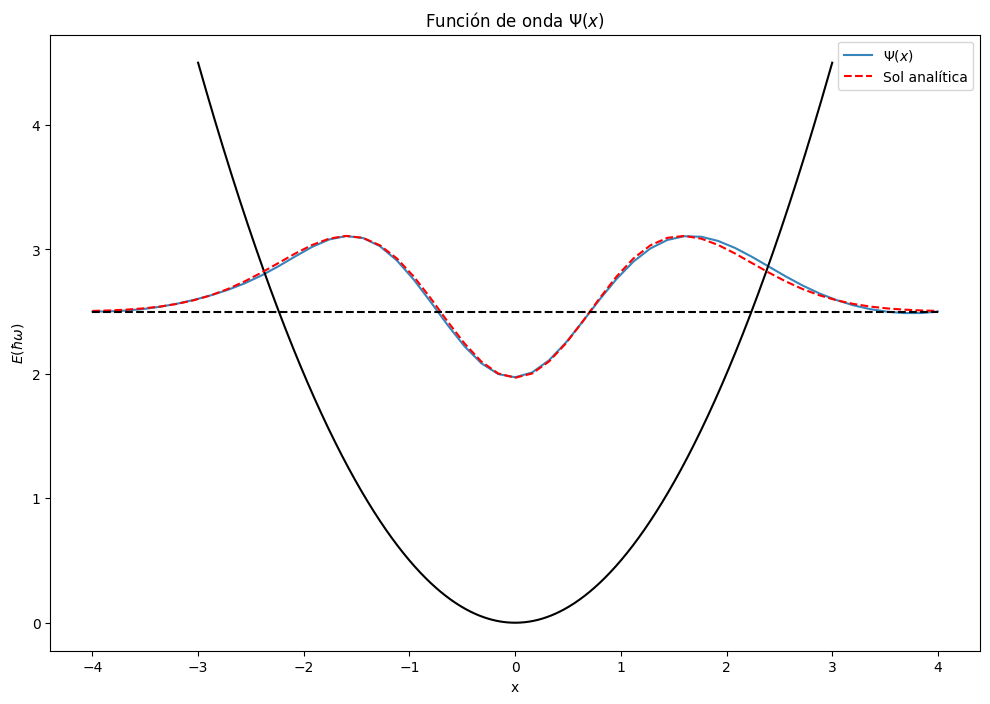

In [ ]:
plt.figure(figsize=(12, 8))
plt.plot(X_grid, 2.5+egparesultQHO2.data[-1,0,:-1], '-', label=f'$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
plt.plot(X_grid, 2.5+APsi2, 'r--', label='Sol analítica')
plt.plot(np.linspace(-4,4,2), np.linspace(2.5,2.5,2), 'k--')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E(\hbar \omega)$')
plt.legend();

In [ ]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_40(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(egparesultQHO2.data.shape[1])):
        plt.plot(X_grid, 2.5+egparesultQHO2.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 2.5+APsi2, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(2.5,2.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_40 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO2.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_40 function
interact(update_plot_cell_40, i=generation_slider_cell_40);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=147), Outp…

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_41(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultQHO2.GP_hist[i].predict(X_grid, return_std=True)
    plt.plot(X_grid, 2.5+mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid.ravel(),
        2.5+ mean_prediction - 1.96 * std_prediction,
        2.5+mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 2.5+1*APsi2, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(2.5,2.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_41 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO2.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_41 function
interact(update_plot_cell_41, i=generation_slider_cell_41);

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=147), Outp…

In [ ]:
Psi2=egparesultQHO2.data[-1, 0, :-1]
cons = 10 ### FACTOR CONSTANTE que MULTIPLICA EL EXPONENTE EN FUNCIÓN DE COSTE 
E2 = np.sqrt(-np.log(-egparesultQHO2.data[-1,0,-1])/cons) # con definición exponencial de función de coste la energía se determina a partir del fitness así
params = {'x':X_grid, 'E0': E0, 'Psi0': Psi_ground, 'E1':E1, 'Psi1': Psi1, 'E2':E2, 'Psi2': Psi2 }

In [ ]:
Gaussian = EGPA(size_gen=800, grid_X=X_grid, max_iter=1000, dead_iter=120, alpha=0.2, elite_factor=0.08, init_kernels=8,parallelize=True, init_data=(X_train, Y_train), analysis_mode=True)
egparesultQHO3 = Gaussian.minimize(oneDHOExpE3, params, exp_from = 5, output_runtime=True)

IT:  0 	Best cost:  [3.27621519]
IT:  1 	Best cost:  [3.26196442]
IT:  2 	Best cost:  [3.06144592]
IT:  3 	Best cost:  [2.79746085]
IT:  4 	Best cost:  [-7.22250107e-12]
IT:  5 	Best cost:  [-1.51236913e-10]
IT:  6 	Best cost:  [-4.97358195e-10]
IT:  7 	Best cost:  [-5.61857507e-09]
IT:  8 	Best cost:  [-3.98535835e-08]
IT:  9 	Best cost:  [-2.07427286e-07]
IT:  10 	Best cost:  [-4.61141001e-07]
IT:  11 	Best cost:  [-6.42824315e-07]
IT:  12 	Best cost:  [-6.02986008e-06]
IT:  13 	Best cost:  [-6.02986008e-06]
IT:  14 	Best cost:  [-9.00355773e-06]
IT:  15 	Best cost:  [-1.89346132e-05]
IT:  16 	Best cost:  [-1.89346132e-05]
IT:  17 	Best cost:  [-1.89346132e-05]
IT:  18 	Best cost:  [-2.31428606e-05]
IT:  19 	Best cost:  [-2.67288705e-05]
IT:  20 	Best cost:  [-2.86749633e-05]
IT:  21 	Best cost:  [-2.87593453e-05]
IT:  22 	Best cost:  [-2.87593453e-05]
IT:  23 	Best cost:  [-3.15292425e-05]
IT:  24 	Best cost:  [-4.20187676e-05]
IT:  25 	Best cost:  [-4.20187676e-05]
IT:  26 	Best co

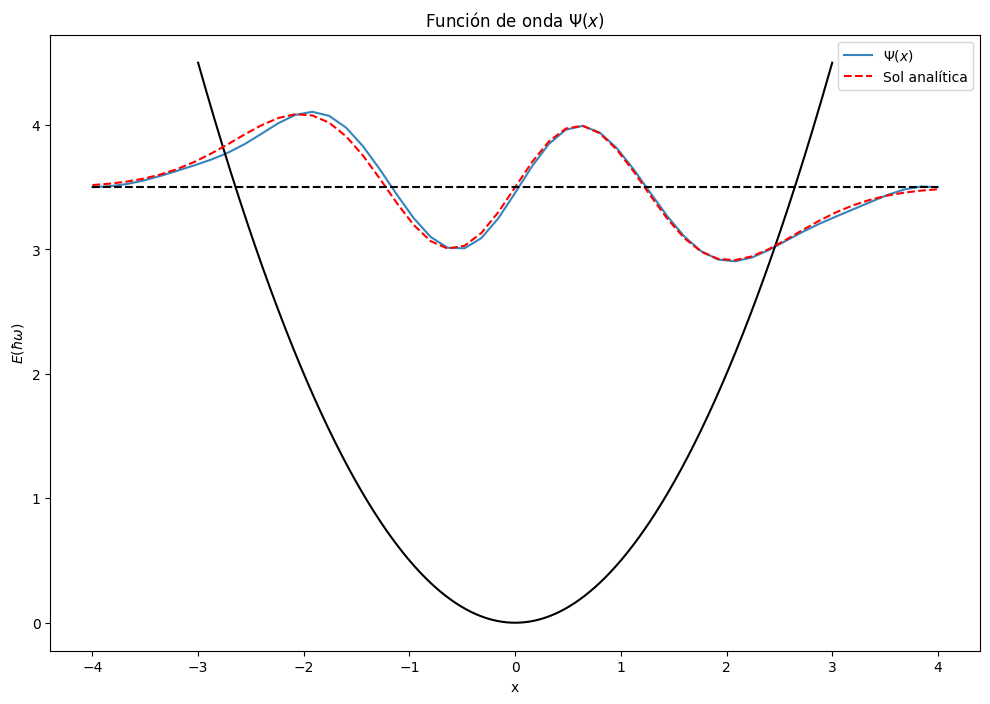

In [ ]:
plt.figure(figsize=(12, 8))
plt.plot(X_grid, 3.5+egparesultQHO3.data[-1,0,:-1], '-', label=f'$\Psi(x)$', alpha=0.9)
plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
plt.plot(X_grid, 3.5+-1*APsi3, 'r--', label='Sol analítica')
plt.plot(np.linspace(-4,4,2), np.linspace(3.5,3.5,2), 'k--')
plt.gca().set_title('Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$E(\hbar \omega)$')
plt.legend();

In [ ]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_45(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(egparesultQHO3.data.shape[1])):
        plt.plot(X_grid, 3.5+egparesultQHO3.data[i,inds,:-1])#, label='Mejores soluciones')

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 3.5+-1*APsi3, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(3.5,3.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_45 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO3.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_45 function
interact(update_plot_cell_45, i=generation_slider_cell_45);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=196), Outp…

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_46(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultQHO3.GP_hist[i].predict(X_grid, return_std=True)
    plt.plot(X_grid, 3.5+mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid.ravel(),
        3.5+ mean_prediction - 1.96 * std_prediction,
        3.5+mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(np.linspace(-3,3, 1000), 0.5*np.linspace(-3,3,1000)**2, 'k-')
    plt.plot(np.linspace(-4,4,n_variables), 3.5+-1*APsi3, 'r--', label='Sol analítica')
    plt.plot(np.linspace(-4,4,2), np.linspace(3.5,3.5,2), 'k--')
    plt.legend();

#Create a slider widget
generation_slider_cell_46 = widgets.IntSlider(value=0, min=0, max=len(egparesultQHO3.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_46 function
interact(update_plot_cell_46, i=generation_slider_cell_46);



# mean_prediction, std_prediction = egparesultQHO3.GP_hist[0].predict(X_grid, return_std=True)
# #plt.scatter(X_train, Y_train, label="Observations")
# plt.plot(X_grid, mean_prediction, label="Mean prediction")
# plt.fill_between(
#     X_grid.ravel(),
#     mean_prediction - 1.96 * std_prediction,
#     mean_prediction + 1.96 * std_prediction,
#     alpha=0.5,
#     label=r"95% confidence interval",
# )
# plt.legend()
# plt.xlabel("$x$")
# plt.ylabel("$f(x)$")
# _ = plt.title("Gaussian process regression on noise-free dataset")

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=196), Outp…

## **Solving Non-Linear Schrödinger Equation**
To solve the Non-Linear Schrödinger Equation we will use an optimization function based on the earlier paper *Applications of Genetic Algorithms to the Solutions of ODEs* by D. A. Diver (1993).

The nonlinear forced harmonic-oscillator problem is a nonlinear ordinary differential equation:

\begin{equation}
\frac{1}{2}y''(x)-\frac{1}{2}y(x)+y(x)^3=0 \quad \tag{1}
\end{equation}

subject to the boundary conditions $y(0)=1$ and $y'(0)=0$.

The analytical solution is $y(x)=\operatorname{sech}(x)$.

Conditions on $y(x)$ are imposed as evidence in the Gaussian process. Conditions on the derivative are imposed in the cost-function definition.

We seek a discretized solution vector
$$
y=[y(x_1),y(x_2),\ldots,y(x_n)].
$$
The cost function is defined in terms of the residuals of candidate solutions in equation (1), using numerical derivatives.

The numerical second derivative is
$$
y''(x) = \frac{d^2y}{dx^2}(x_i)=\frac{y(x_{i-1})+y(x_{i+1})-2y(x_i)}{h^2},
$$
where $h=x_i-x_{i-1}$ is constant for our fixed grid.

The cost function for a candidate solution $y$ is
\begin{equation}
R=\sum_i R_i = \sum_i\left[\frac{1}{2}\left[\frac{y(x_{i-1})+y(x_{i+1})-2y(x_i)}{h^2}\right]-\frac{1}{2}y(x_i)+y(x_i)^3\right].
\end{equation}

Here, $R_i$ are the residuals obtained by applying the numerical derivative definitions to the differential equation at $x_i$. If $y(x)$, represented by the values $y_i=y(x_i)$, is a solution, then $R_i=0$ for every $i$. The value $y'^*$ is a user-defined gradient at a point, used to enforce possible boundary conditions on $y'(x)$.

The derivative-boundary penalty is
\begin{equation}
D=e^{\left|y'(0)-y^{*\prime}(0)\right|}-1.
\end{equation}

Finally, the objective can be written as
$$
Z=R+\alpha D \in [0,\infty),
$$


In [ ]:
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
# Add the main directory to sys.path
sys.path.append(main_dir)
from OptFunctions.NonLinearSE import *
from EGPA import *
import numpy as np
import warnings
warnings.filterwarnings("ignore")

In [ ]:
L=2
n_variables = 51
X_grid = np.linspace(start=-1, stop=1, num=n_variables).reshape(-1,1) #para que sean n_variables filas y 1 columna
#Ahora definimos las observaciones que hemos hecho de la función. En este caso son las condiciones de contorno del problema
#Los datos que conocemos son las amplitudes en x=0 que son 1
#X_train = X_grid[n_variables//2]
X_train = np.array((0)).reshape(-1,1)
Y_train = np.linspace(start=1, stop=1, num=1).reshape(-1,1) #Para que sea 2D array
params = {'L':L}

In [ ]:
print(r' Analytical solution sech(x) on optimization function:', '\n Non exp problem definition (opt defined at 0) yields:',
NLSE(1/np.cosh(X_grid[:,0]), L=2, exponential=False), '\n exp problem definition (opt defined at -1) yields:', 
NLSE(1/np.cosh(X_grid[:,0]), L=2, exponential=True))

 Analytical solution sech(x) on optimization function: 
 Non exp problem definition (opt defined at 0) yields: 3.946398776202425518 
 exp problem definition (opt defined at -1) yields: -0.96130457209627424457


In [ ]:
Gaussian = EGPA(size_gen=200, grid_X=X_grid, max_iter=400, dead_iter=50, alpha=0.03, elite_factor=0.02, init_kernels=8 ,parallelize=True, init_data=(X_train, Y_train), normalize_solutions=False, symmetrize_solutions=False, analysis_mode=True)
egparesultNLSE = Gaussian.minimize(NLSE, params, exp_from = 3000, output_runtime=True)

IT:  0 	Best cost:  4043.243198479869914
IT:  1 	Best cost:  520.8261141185449132
IT:  2 	Best cost:  263.09923152890122106
IT:  3 	Best cost:  197.42589028486759736
IT:  4 	Best cost:  197.42589028486759736
IT:  5 	Best cost:  197.42589028486759736
IT:  6 	Best cost:  197.42589028486759736
IT:  7 	Best cost:  197.42589028486759736
IT:  8 	Best cost:  189.04866208454159165
IT:  9 	Best cost:  189.04866208454159165
IT:  10 	Best cost:  189.04866208454159165
IT:  11 	Best cost:  189.04866208454159165
IT:  12 	Best cost:  189.04866208454159165
IT:  13 	Best cost:  189.04866208454159165
IT:  14 	Best cost:  189.04866208454159165
IT:  15 	Best cost:  189.04866208454159165
IT:  16 	Best cost:  189.04866208454159165
IT:  17 	Best cost:  189.04866208454159165
IT:  18 	Best cost:  189.04866208454159165
IT:  19 	Best cost:  189.04866208454159165
IT:  20 	Best cost:  189.04866208454159165
IT:  21 	Best cost:  189.04866208454159165
IT:  22 	Best cost:  189.04866208454159165
IT:  23 	Best cost:  18

In [ ]:
egparesultNLSE.best_sampled.shape

(59, 1, 52)

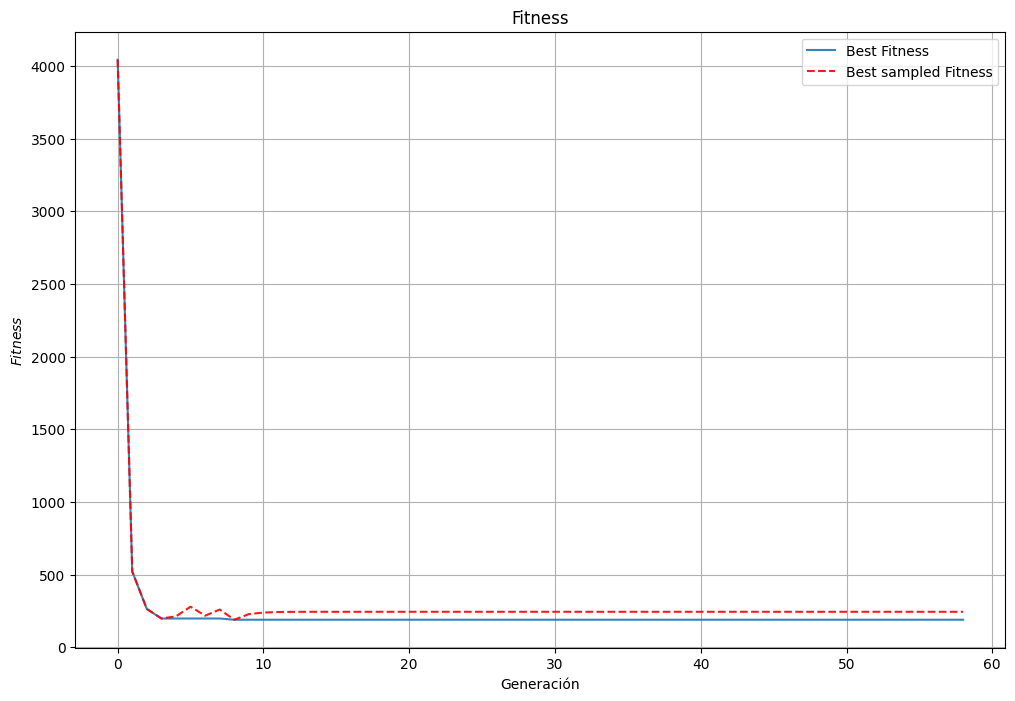

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.arange(0, len(egparesultNLSE.data), 1),egparesultNLSE.data[:,0,-1], '-', label='Best Fitness', alpha=0.9)
plt.plot(np.arange(0, len(egparesultNLSE.data), 1),egparesultNLSE.best_sampled[:, 0, -1], 'r--', label='Best sampled Fitness', alpha=0.9)
# plt.ylim((-1, 0.2))
# plt.xlim((38, 75))
plt.grid()
plt.gca().set_title(r'Fitness')
plt.xlabel('Generación')
plt.gca().set_ylabel(r'$Fitness$')
plt.legend(loc = 'upper right');

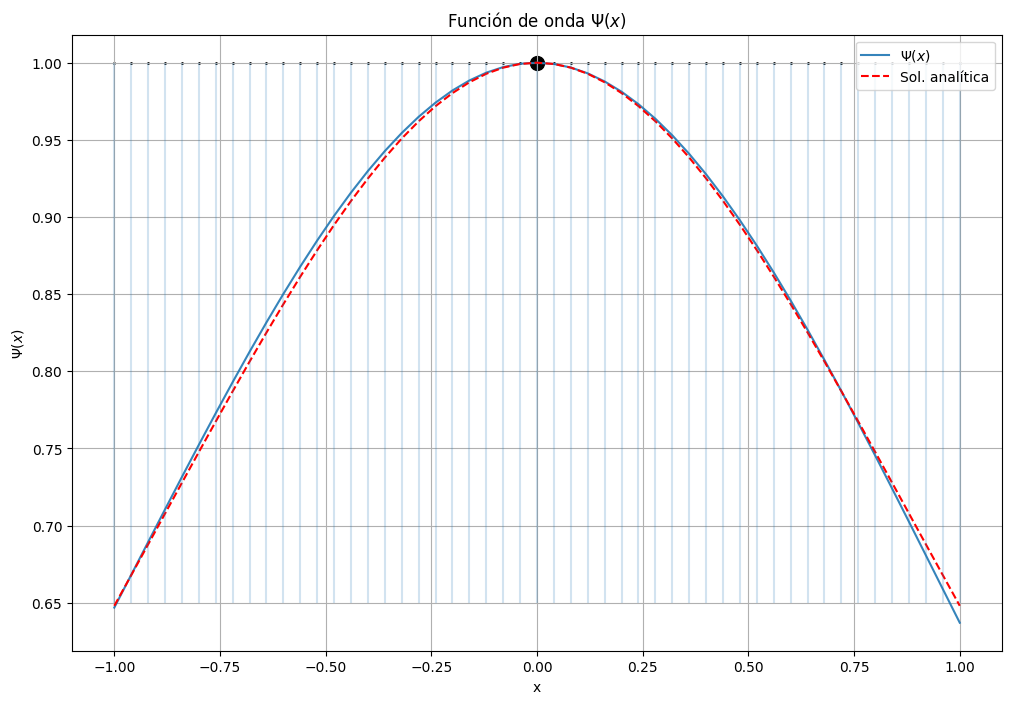

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))

plt.plot(np.linspace(-1, 1, n_variables),egparesultNLSE.data[-1,0,:-1], '-', label='$\Psi(x)$', alpha=0.9)
plt.plot(X_grid[:, 0], 1/np.cosh(X_grid[:,0]), 'r--', label='Sol. analítica')
plt.scatter(X_grid[n_variables//2, 0], 1, s=100, c='black')
plt.scatter(X_grid[:, 0], n_variables*[1], s=1, c='black')
for i in range(len(X_grid[:, 0])):
    plt.vlines(x=X_grid[i,0], ymin=0.65, ymax=1, alpha=0.2)
plt.grid()
plt.gca().set_title(r'Función de onda $\Psi(x)$')
plt.xlabel('x')
plt.gca().set_ylabel(r'$\Psi(x)$')
plt.legend(loc = 'upper right');

In [ ]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_64(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    for inds in range(int(len(egparesultNLSE.data[0, :,-1]))):
        plt.plot(X_grid[:, 0], egparesultNLSE.data[i,inds,:-1])#, label='Mejores soluciones')
    
    plt.plot(X_grid[:, 0], 1/np.cosh(X_grid[:,0]), 'r--', label='Sol. analítica')
    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.legend();

#Create a slider widget
generation_slider_cell_64 = widgets.IntSlider(value=0, min=0, max=len(egparesultNLSE.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_64 function
interact(update_plot_cell_64, i=generation_slider_cell_64);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=58), Outpu…

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot_cell_65(i):
    plt.clf()  # Clear previous plot
    plt.figure(figsize=(20, 12))
    plt.suptitle(f'Generation number {i}')
    
    


    mean_prediction, std_prediction = egparesultNLSE.GP_hist[i].predict(X_grid, return_std=True)
    plt.plot(X_grid, mean_prediction, label="Mean prediction")
    plt.fill_between(
        X_grid.ravel(),
        mean_prediction - 1.96 * std_prediction,
        mean_prediction + 1.96 * std_prediction,
        alpha=0.5,
        label=r"95% confidence interval",
    )

    plt.gca().set_title('Función de onda $\Psi(x)$')
    plt.xlabel('x')
    plt.gca().set_ylabel(r'$\Psi(x)$')
    plt.plot(X_grid[:, 0], 1/np.cosh(X_grid[:,0]), 'r--', label='Sol. analítica')
    plt.legend();

#Create a slider widget
generation_slider_cell_65 = widgets.IntSlider(value=0, min=0, max=len(egparesultNLSE.data)-2, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot_cell_65 function
interact(update_plot_cell_65, i=generation_slider_cell_65);

interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=57), Outpu…